In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy.io import loadmat

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect
from collections import Counter
from itertools import product

import h5py

import regex as re


main_dir = '/home/cparis/00PhD/DS_PCBreview/'
# main_dir = 'C:/Users/Carlo PARIS/00PhD Code/DS_PCBreview/'
data_dir1 = main_dir+'Data folder/Franke_extra_data/16_directions_spaced_22_degrees/'
data_dir2 = main_dir+'Data folder/Franke_extra_data/narrow_angles/'

print(os.listdir(data_dir1),'\n')

['30Aug2012_x100.mat', '18Sep2012_x100.mat', '23Aug2012_x100.mat', '20Sep2012_1_x50.mat', '20Sep2012_2_x50.mat', '19Apr2012_x10.mat', '19Jun2012_x10.mat'] 



/home/cparis/anaconda3/lib/python3.7/site-packages/statsmodels/compat/pandas.py:49: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  data_klasses = (pandas.Series, pandas.DataFrame, pandas.Panel)


## Data exploration and formatting

['30Aug2012_x100.mat', '18Sep2012_x100.mat', '23Aug2012_x100.mat']
dict_keys(['BAR_DIR', 'BAR_RGB', 'BAR_VEL', 'SPIKE_COUNTS_ALL'])
30Aug2012_x100.mat
Number of directions: 16
[800.]
[  0.  22.  45.  67.  90. 112. 135. 157. 180. 202. 225. 247. 270. 292.
 315. 337.]
(7, 16, 100)
100
BAR_DIR (1600,)
[  0.   0.   0. ... 337. 337. 337.]
BAR_RGB (1600,)
[38. 38. 38. ... 38. 38. 38.]
BAR_VEL (1600,)
[800. 800. 800. ... 800. 800. 800.]
SPIKE_COUNTS_ALL (7, 1600)
[[ 0.  4.  1. ... 19. 13. 17.]
 [ 0.  2.  0. ...  1.  2.  3.]
 [62. 62. 58. ... 69. 69. 63.]
 ...
 [ 4.  3.  0. ...  3.  7.  5.]
 [33. 30. 38. ... 32. 30. 24.]
 [ 3.  1.  0. ...  1.  1.  2.]]




dict_keys(['BAR_DIR', 'BAR_RGB', 'BAR_VEL', 'SPIKE_COUNTS_ALL'])
18Sep2012_x100.mat
Number of directions: 16
[800.]
[  0.  22.  45.  67.  90. 112. 135. 157. 180. 202. 225. 247. 270. 292.
 315. 337.]
(10, 16, 100)
100
BAR_DIR (1600,)
[  0.   0.   0. ... 337. 337. 337.]
BAR_RGB (1600,)
[38. 38. 38. ... 38. 38. 38.]
BAR_VEL (1600,)
[800. 800. 80

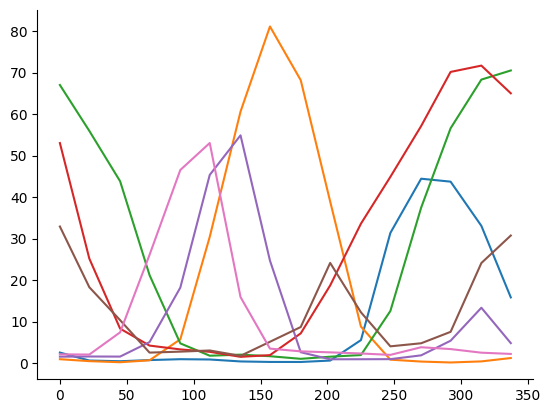

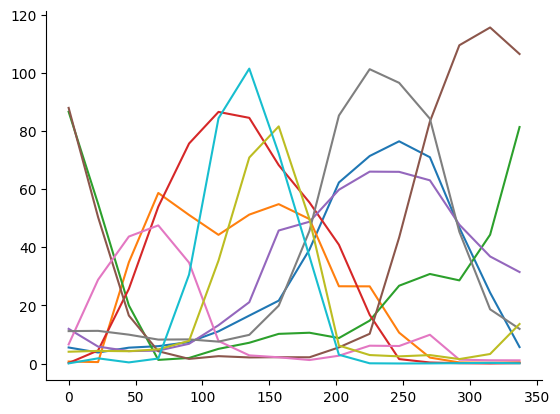

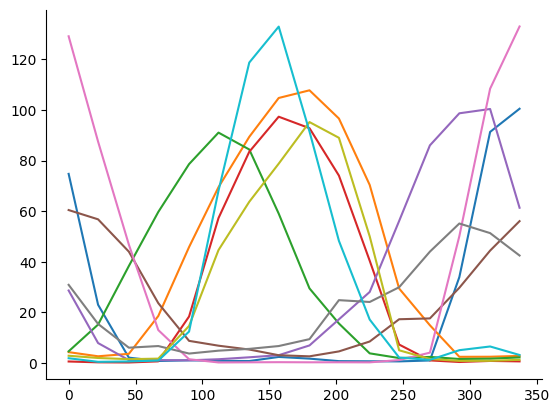

In [2]:
def h5_to_dict(obj):
    if isinstance(obj, h5py.Dataset):
        return obj[()]
    elif isinstance(obj, h5py.Group):
        return {key: np.squeeze(h5_to_dict(obj[key])) for key in obj.keys()}

exp_list = [el for el in os.listdir(data_dir1) if 'x100' in el]
# exp_list = np.copy(os.listdir(data_dir1))
print(exp_list)

for el in exp_list:
    with h5py.File(data_dir1+el, 'r') as f:
#         print(list(f.keys()))  # see what's inside
    #     d1 = f['variable_name'][:]
        d1 = h5_to_dict(f)
    # d1 = loadmat(data_dir1+'18Sep2012_x100.mat')
    print(d1.keys())
    c = Counter(d1['BAR_DIR'])
    print(el)
    print('Number of directions:',len(c.keys()))
    print(np.unique(d1['BAR_VEL']))
    print(np.unique(d1['BAR_DIR']))
    
    dirs = np.unique(d1['BAR_DIR'])
    reps = int(d1['BAR_DIR'].shape[0]/dirs.shape[0])
    tc_data = d1['SPIKE_COUNTS_ALL'].reshape(d1['SPIKE_COUNTS_ALL'].shape[0], dirs.shape[0], reps)
    
    plt.figure()
    plt.plot(dirs, tc_data.mean(axis=2).T)
    print(tc_data.shape)
    print(reps)
    for key in d1.keys():
        print(key, d1[key].shape)
        print(d1[key])
    print('\n\n\n')
    np.savez(f'./Data folder/Franke_extra_data/{os.path.splitext(el)[0]}_prepped.npz',bar_vel = np.unique(d1['BAR_VEL']), \
                                                                dirs=dirs, n_reps = reps, raw_tc_data=tc_data,\
                                                                mean_tcs = tc_data.mean(axis=2), allow_pickle=True)

## Fitting FTVMs and eliminating those with MSE>15

30Aug2012_x100_prepped
dict_keys(['bar_vel', 'dirs', 'n_reps', 'raw_tc_data', 'mean_tcs', 'allow_pickle'])
[ True  True  True  True  True False  True]
[[ 0.          1.31670301]
 [ 1.          0.81560367]
 [ 2.          2.16592138]
 [ 3.         10.60896132]
 [ 4.          9.41269436]
 [ 5.         27.58132374]
 [ 6.          3.08892699]]
[3. 1. 3. 3. 1. 3. 1.]
[[None None None None]]
18Sep2012_x100_prepped
dict_keys(['bar_vel', 'dirs', 'n_reps', 'raw_tc_data', 'mean_tcs', 'allow_pickle'])
[ True False False  True  True  True  True  True  True  True]
[[ 0.          9.33647605]
 [ 1.         72.67372842]
 [ 2.         57.68902402]
 [ 3.         12.0575553 ]
 [ 4.          9.78764782]
 [ 5.          1.80517128]
 [ 6.          5.28773673]
 [ 7.          3.8594496 ]
 [ 8.          8.54476992]
 [ 9.          7.54477217]]
[2. 1. 3. 1. 2. 3. 0. 2. 1. 1.]
[[6 3 0 5]
 [6 3 4 5]
 [6 3 7 5]
 [6 8 0 5]
 [6 8 4 5]
 [6 8 7 5]
 [6 9 0 5]
 [6 9 4 5]
 [6 9 7 5]]
23Aug2012_x100_prepped
dict_keys(['bar_v

/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:51: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).


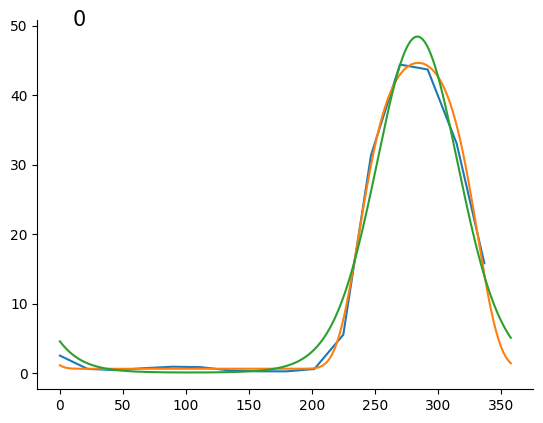

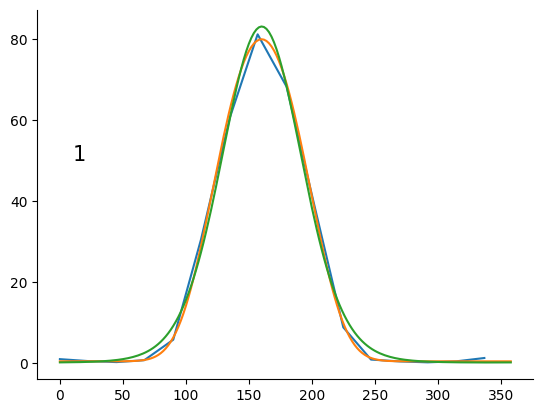

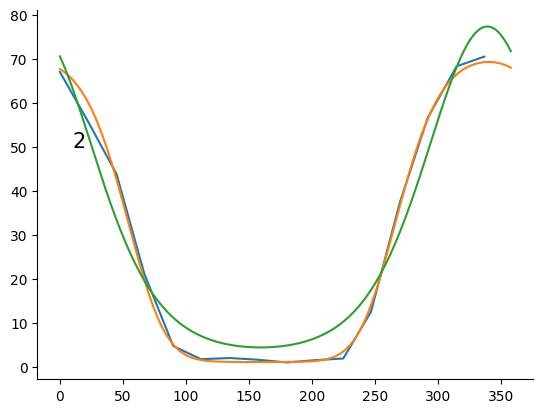

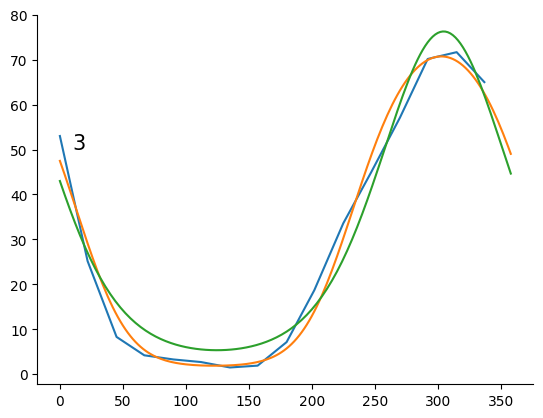

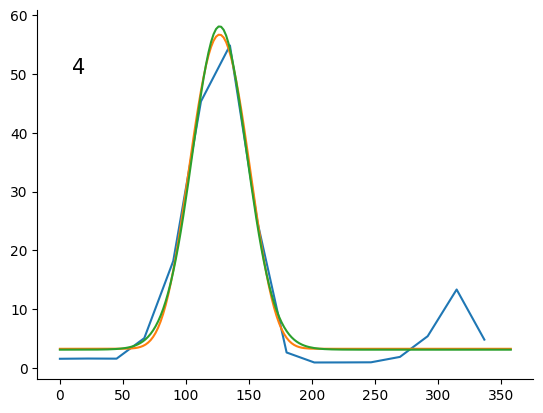

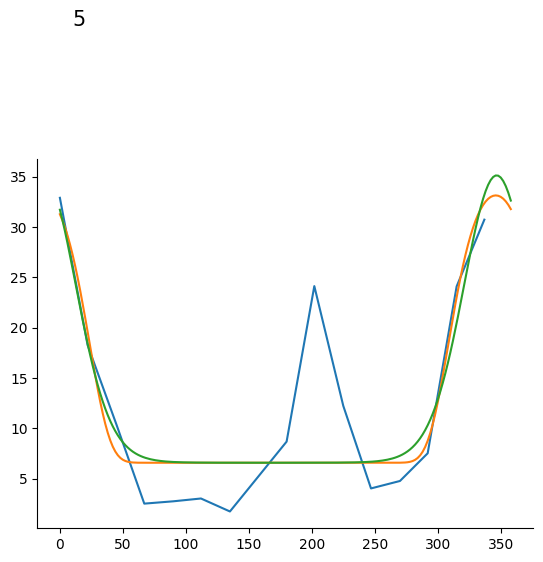

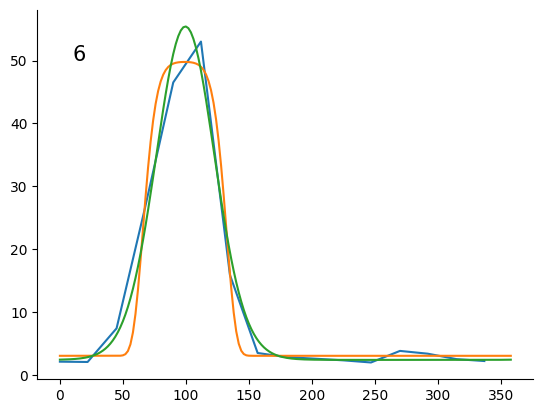

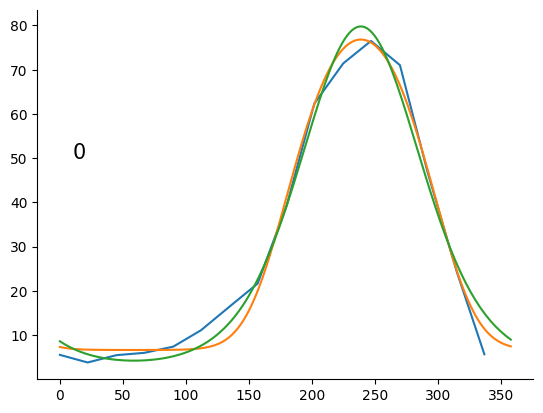

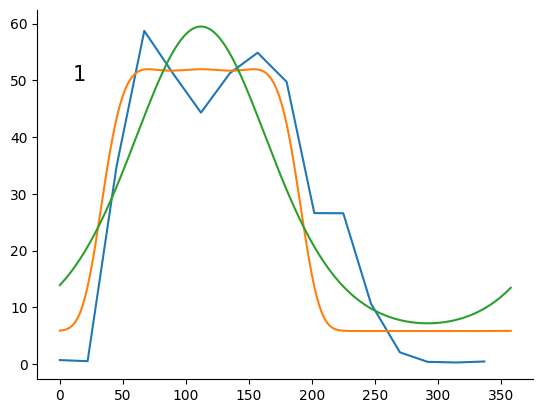

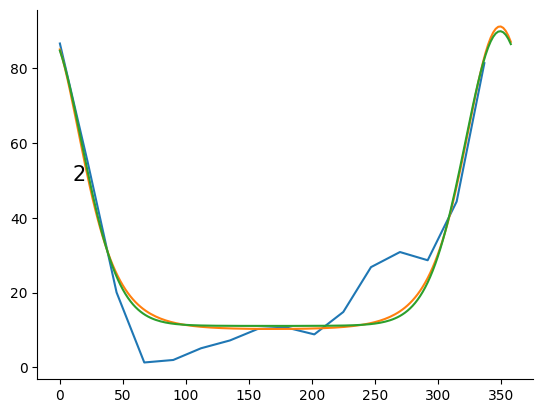

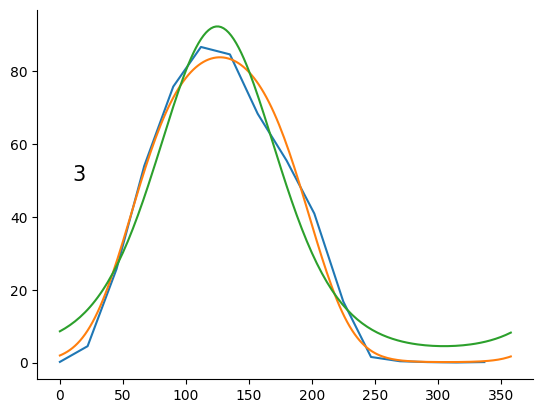

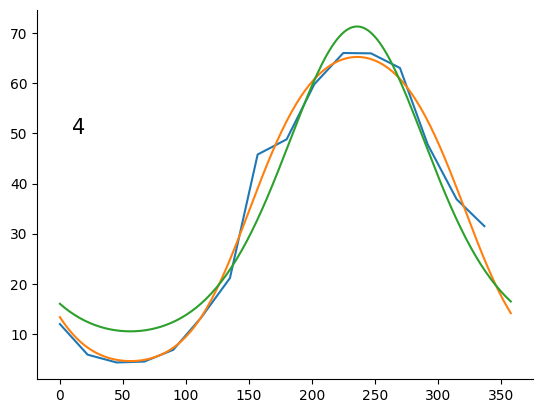

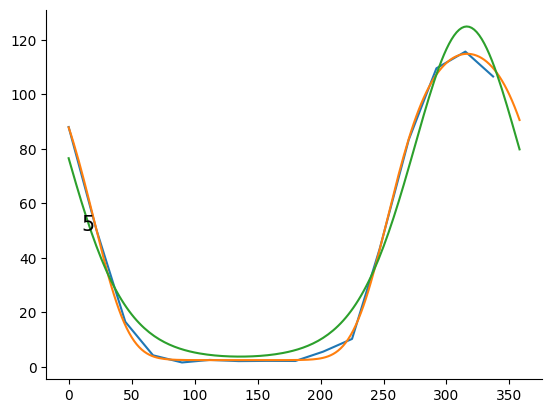

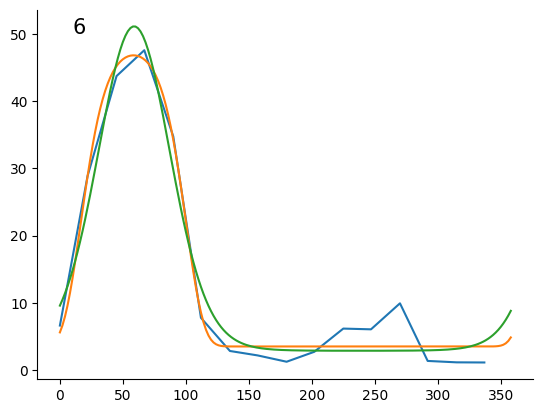

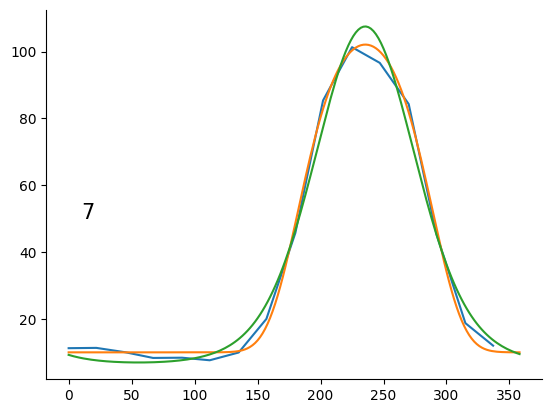

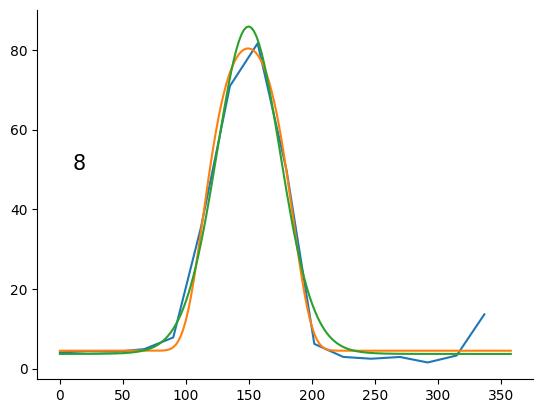

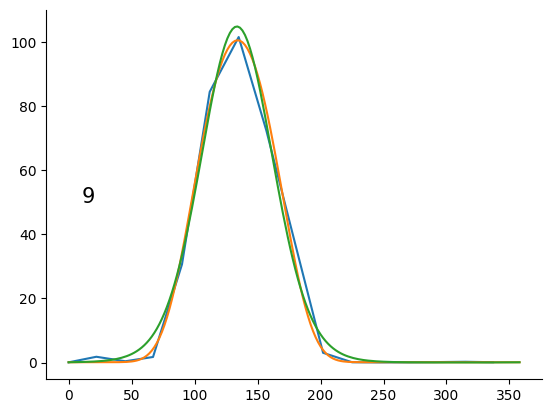

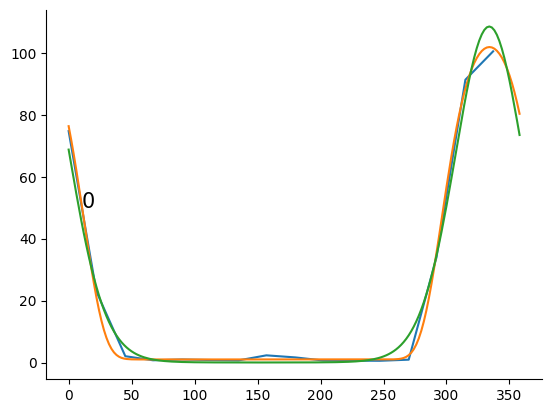

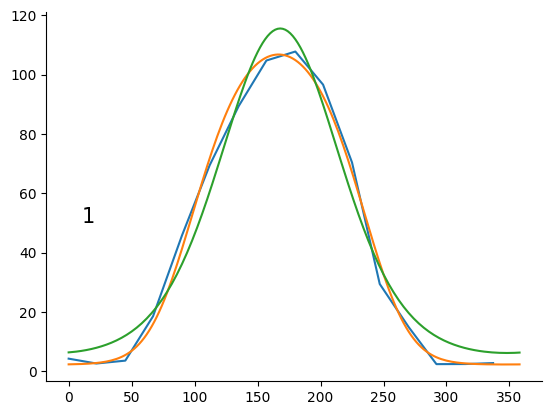

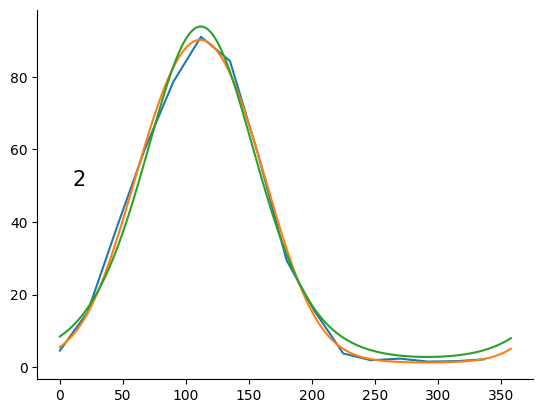

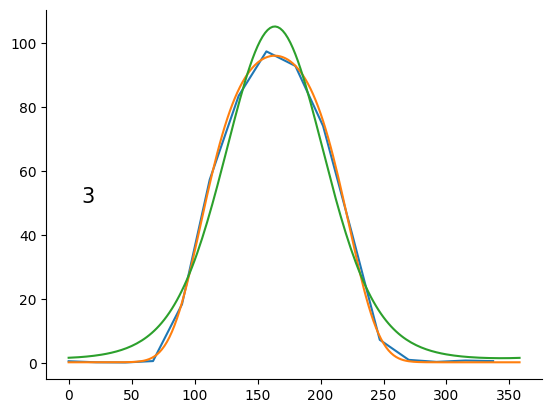

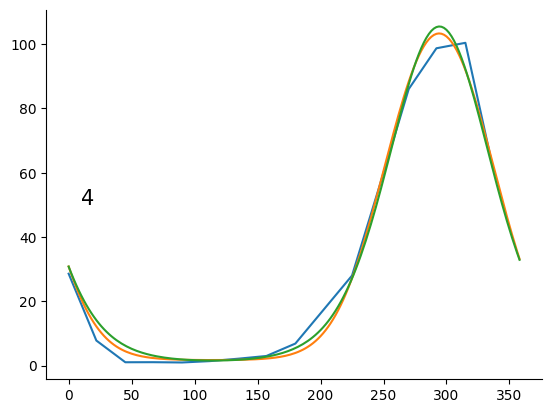

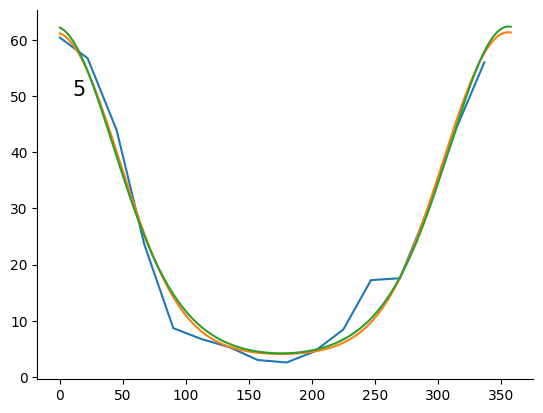

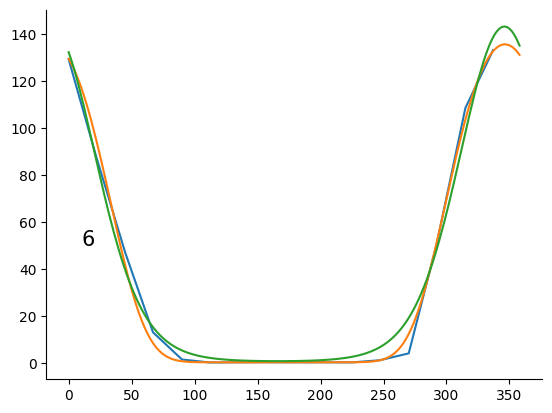

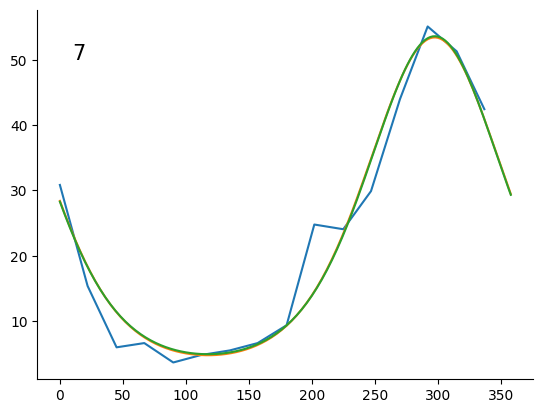

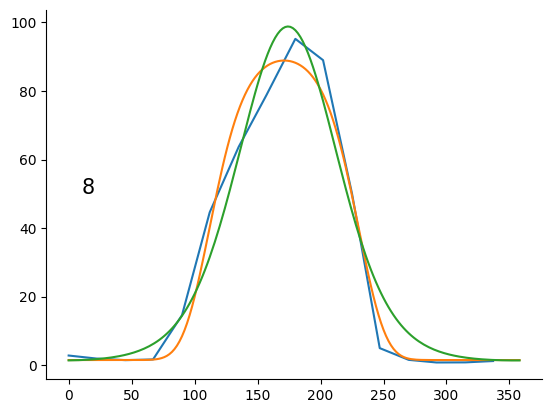

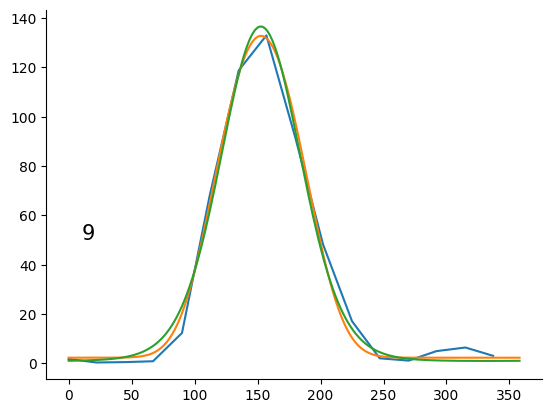

In [49]:
work_dir = './Data folder/Franke_extra_data/'
datafiles = [f for f in os.listdir(work_dir) if f.endswith('.npz') and 'x100' in f]

plt_idx = 0

big_bool_arr = np.array([], dtype = int)
# big_idx_arr = np.array([])
big_quadrant_arr = np.array([], dtype = int)
for file in datafiles:
    match = re.match(r'^(.*)\.npz$', file)
    if match:
        filename = match.group(1)
        
    print(filename)
    all_vm_fit_parameters = []
    all_ftvm_fit_parameters = []
    mse_ftvm_fit = []
    
    
    data_dict = dict(np.load(work_dir+file))
    mean_tcs = data_dict['mean_tcs']
    stim = data_dict['dirs']
    
    print(data_dict.keys())
    for idx in range(len(mean_tcs)):
        peak_stim = stim[np.argmax(mean_tcs[idx])]
        max_a=np.sum(mean_tcs[idx])
        max_tc = np.max(mean_tcs[idx])
        one_vm_fit_parameters, _ = curve_fit(ssiMod.VON_MISES, stim, mean_tcs[idx], \
                                             p0 = (max_a, peak_stim, 1, 0), \
                                             bounds = ((0, peak_stim-45,1e-3, 0),\
                                                       (3*max_a,peak_stim+45,2, max_tc/5)))
        all_vm_fit_parameters += [one_vm_fit_parameters] 

        ftvm_parameter_guess = np.append(one_vm_fit_parameters, 0)     #guess g is 0.     parameters = (a, th_0, s, baseline, g)
        one_ftvm_fit_parameters, _ = curve_fit(ssiMod.FTVM, stim, mean_tcs[idx], \
                                               p0 = ftvm_parameter_guess, \
                                               bounds = ((0, peak_stim-45, 1e-3, 0, -180),\
                                                         (3*max_a, peak_stim+45, 2, max_tc/5,  180)))

        all_ftvm_fit_parameters += [one_ftvm_fit_parameters]

    all_ftvm_fit_parameters = np.array([np.array(el) for el in all_ftvm_fit_parameters])

    ftvm_fit = np.empty((0,len(stim)))
    
    ftvm_fit = np.array([ssiMod.FTVM(stim, *pars) for pars in all_ftvm_fit_parameters])
    mse_ftvm_fit = np.array([[idx, el] for idx, el in enumerate(np.mean((mean_tcs-ftvm_fit)**2, axis=1))])
    
    for idx in range(len(mean_tcs)): 
        plt.figure()
        plt.plot(stim, mean_tcs[idx])
        plt.plot(np.arange(0,360,2), ssiMod.FTVM(np.arange(0,360,2), *all_ftvm_fit_parameters[idx]))
        plt.plot(np.arange(0,360,2), ssiMod.VON_MISES(np.arange(0,360,2), *all_vm_fit_parameters[idx]))
        plt.text(10,50, mse_ftvm_fit[idx, 0].astype(int), size = 15)
    good_cell_idxs = np.array(mse_ftvm_fit)[:,1]<=15
    print(good_cell_idxs)
    print(mse_ftvm_fit)
    mse_ftvm_fit = np.array(mse_ftvm_fit)
    cell_quadrants = ((all_ftvm_fit_parameters[:,1])%360)//90   
    print(cell_quadrants)
#     for quad in [0,1,2,3]:
#         print(mse_ftvm_fit[np.where(cell_quadrants==quad)[0],0])
#         print(mse_ftvm_fit[0][good_cell_idxs[np.where(cell_quadrants==quad)[0]]])
    cell_quads_sep = [list(np.array(mse_ftvm_fit[np.where(cell_quadrants==quad)[0],0]\
                      [good_cell_idxs[np.where(cell_quadrants==quad)[0]]], dtype = int)) for quad in [0,1,2,3]]
    quad_idxs = np.atleast_1d(list(product(*cell_quads_sep))) if np.atleast_1d(list(product(*cell_quads_sep))).size\
                    else np.atleast_2d(np.full(4, None))
    print(quad_idxs)
#     print(cell_quads_sep)
    all_ftvm_fit_parameters[:,1] = (all_ftvm_fit_parameters[:,1]-45)%360
    data_dict['all_ftvm_fit_parameters'] = all_ftvm_fit_parameters
    data_dict['mse_ftvm_fit'] = mse_ftvm_fit
    data_dict['idx_cells_mse_leq10'] = good_cell_idxs
    data_dict['cell_quadrants'] = cell_quadrants
    data_dict['cell_idx_x_quad'] = cell_quads_sep
    data_dict['quad_indices'] = quad_idxs
    with open(work_dir+filename+'.pkl', 'wb') as rick:
        pickle.dump(data_dict, rick, protocol=4)
    
    big_bool_arr = np.append(big_bool_arr, good_cell_idxs)
    big_quadrant_arr = np.append(big_quadrant_arr,cell_quadrants).astype(int)

In [54]:
dicts = []
for f in datafiles:
    match = re.match(r'^(.*)\.npz$', f)
    if match:
        filename = match.group(1)
    with open(work_dir+filename+'.pkl', "rb") as fh:
        dicts.append(pickle.load(fh))
all_exp_data={}
for key in dicts[0].keys():
    try:
        all_exp_data[key] = np.concatenate(
            [np.atleast_1d(d[key]) for d in dicts],
            axis=0)
    except: print(key)
print(all_exp_data.keys())
big_bool_arr = all_exp_data['idx_cells_mse_leq10']
big_quadrant_arr = all_exp_data['cell_quadrants']
all_cell_quads_sep = np.array([list(np.array(np.arange(len(big_bool_arr))[np.where(big_quadrant_arr==quad)[0]]\
                      [big_bool_arr[np.where(big_quadrant_arr==quad)[0]].astype(bool)], dtype = int)) for quad in [0,1,2,3]])
print(all_cell_quads_sep)
all_quad_idx = np.array(list(product(*all_cell_quads_sep)))
print(all_quad_idx.shape)
all_exp_data['all_cell_quads_sep'] = all_cell_quads_sep
all_exp_data['quad_indices'] = all_quad_idx


with open(work_dir+f'all_exp_data.pkl', 'wb') as rick:
    pickle.dump(all_exp_data, rick, protocol = 4)


dict_keys(['bar_vel', 'dirs', 'n_reps', 'raw_tc_data', 'mean_tcs', 'allow_pickle', 'all_ftvm_fit_parameters', 'mse_ftvm_fit', 'idx_cells_mse_leq10', 'cell_quadrants', 'cell_idx_x_quad', 'quad_indices'])
[list([13]) list([1, 4, 6, 10, 15, 16, 18, 19, 20, 26]) list([7, 11, 14])
 list([0, 2, 3, 12, 17, 21, 22, 23, 24])]
(270, 4)


/home/cparis/anaconda3/lib/python3.7/site-packages/numpy/core/shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = asanyarray(ary)
/home/cparis/anaconda3/lib/python3.7/site-packages/numpy/core/shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = asanyarray(ary)
/home/cparis/anaconda3/lib/python3.7/site-packages/numpy/core/shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated

## Calculate quadruplet TCs, SSI, \rho and width-dependent minSSI

In [55]:
theta_step = 2

# dat_dir_out = '/home/cparis/00PhD/'
# dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/'

area_or_max = 'Area'
dat_dir_out = f'/home/cparis/00PhD/Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())
all_multipliers = data_dict['all_multipliers']
bio_idx = np.where(all_multipliers==1)[0][0]
print(bio_idx)

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])
34


In [ ]:
from concurrent.futures import ProcessPoolExecutor
def process_width(tc_width):
    return [ssiMod.MC_SSI(tc_quad) for tc_quad in tc_width]

In [58]:
work_dir = './Data folder/Franke_extra_data/'
# datafiles = [f for f in os.listdir(work_dir) if f.endswith('_prepped.pkl') and 'x100' in f]
datafiles = ['all_exp_data.pkl']
print(datafiles)
stim = np.arange(0,360,2)

for filename in datafiles:
    print(filename)
    with open(work_dir+filename, 'rb') as rick:
        data_dict = pickle.load(rick)
#     print(data_dict.keys())
#     print(data_dict['quad_indices'].shape)
#     print(data_dict['all_ftvm_fit_parameters'])
    all_quad_pars = np.tile(np.copy(data_dict['all_ftvm_fit_parameters'][data_dict['quad_indices']])[:,None,:,:],\
                            (1,len(all_multipliers),1,1))
#     print(all_quad_pars[:,:,:,2].shape)
    all_quad_pars[:,:,:,2]*= all_multipliers[None,:,None]
    all_quad_tcs = np.array([[[ssiMod.FTVM(stim, *pars) for pars in quad_pars] for quad_pars in width]\
                           for width in all_quad_pars])
    print(all_quad_tcs.shape)
    all_quad_fwhm = np.array([[[ssiMod.FWHM(pars)[1] for pars in quad] for quad in width] for width in all_quad_pars])
    all_ssis = np.array([[ssiMod.MC_SSI(tc_quad) for tc_quad in tqdm(tc_width)] \
                                for tc_width in tqdm(all_quad_tcs)])
    
    with ThreadPoolExecutor(max_workers=3) as executor:
        all_ssis = np.array(list(tqdm(executor.map(process_width, all_quad_tcs),total=len(all_quad_tcs))))
    
    data_dict['all_quad_pars'] = all_quad_pars
    data_dict['all_quad_tcs'] = all_quad_tcs
    data_dict['all_ssis'] = all_ssis
    data_dict['all_quad_fwhm'] = all_quad_fwhm
    
    with open(work_dir+'ssi_results_'+filename+'.pkl', 'wb') as rick:
        pickle.dump(data_dict, rick, protocol = 4)
        
    print('\n\n\n')

['all_exp_data.pkl']
all_exp_data.pkl
(270, 56, 4, 180)


  0%|          | 0/270 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

...

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

In [59]:
print(data_dict.keys())

dict_keys(['bar_vel', 'dirs', 'n_reps', 'raw_tc_data', 'mean_tcs', 'allow_pickle', 'all_ftvm_fit_parameters', 'mse_ftvm_fit', 'idx_cells_mse_leq10', 'cell_quadrants', 'cell_idx_x_quad', 'quad_indices', 'all_cell_quads_sep', 'all_quad_pars', 'all_quad_tcs', 'all_ssis', 'all_quad_fwhm'])


In [61]:
theta_step = 2

dat_dir_out = '/home/cparis/00PhD/'
# dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/'

area_or_max = 'Area'
dat_dir_out = f'/home/cparis/00PhD/Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    old_data_dict = pickle.load(rick)
print(old_data_dict.keys())
data_dict['all_multipliers'] = np.copy(old_data_dict['all_multipliers'])
with open(work_dir+'ssi_results_'+filename, 'wb') as rick:
        pickle.dump(data_dict, rick, protocol = 4)

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])
